In [ ]:
Problem Statement:Implement Decision Tree and Naïve Bayes classifiers, compare their performance using evaluation metrics, and identify the best model.
    
Name: Rohan Prakash Wayal
Roll no: TE-A-68


In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [5]:
from sklearn.model_selection import train_test_split

In [6]:
from sklearn.preprocessing import LabelEncoder

In [7]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [8]:
from sklearn.naive_bayes import GaussianNB

In [9]:
from sklearn.metrics import(
accuracy_score,
precision_score,
recall_score,
f1_score,
confusion_matrix,
classification_report
)

In [10]:
df=pd.read_csv("Iris.csv")

In [11]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [12]:
("Rows:", df.shape[0])

('Rows:', 150)

In [13]:
("Columns", df.shape[1])

('Columns', 6)

In [14]:
(df.columns.tolist())

['Id',
 'SepalLengthCm',
 'SepalWidthCm',
 'PetalLengthCm',
 'PetalWidthCm',
 'Species']

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [16]:
df.isnull().sum()

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [17]:
df["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [18]:
df = df.drop("Id", axis=1)

In [19]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [20]:
X= df.drop("Species", axis =1)

In [21]:
y = df["Species"]

In [22]:
label_encoder = LabelEncoder()

In [23]:
y = label_encoder.fit_transform(y)

In [24]:
("Encoder Classes:", label_encoder.classes_)

('Encoder Classes:',
 array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object))

In [25]:
("Feature Shape:", X.shape)

('Feature Shape:', (150, 4))

In [26]:
("Target Shape:", y.shape)

('Target Shape:', (150,))

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.20,
random_state=42,
stratify=y
)

In [28]:
("Training Samples:", X_train.shape[0])

('Training Samples:', 120)

In [29]:
("Testing Samples:", X_test.shape[0])

('Testing Samples:', 30)

In [30]:
dt = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

In [31]:
dt.fit(X_train , y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [32]:
dt_pred = dt.predict(X_test)

In [33]:
dt_accuracy = accuracy_score(y_test, dt_pred)

In [34]:
dt_precision = precision_score(y_test, dt_pred, average="weighted")

In [35]:
dt_recall = recall_score(y_test, dt_pred, average="weighted")

In [36]:
dt_f1 = f1_score(y_test, dt_pred, average="weighted")

In [37]:
("Decision Tree")

'Decision Tree'

In [38]:
("Accuracy :", dt_accuracy)

('Accuracy :', 0.9333333333333333)

In [39]:
("Precision:", dt_precision)

('Precision:', 0.9333333333333333)

In [40]:
("Recall   :", dt_recall)

('Recall   :', 0.9333333333333333)

In [41]:
("F1-Score :", dt_f1)

('F1-Score :', 0.9333333333333333)

In [42]:
print(classification_report(
        y_test,
        dt_pred,
        target_names=label_encoder.classes_)
)

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



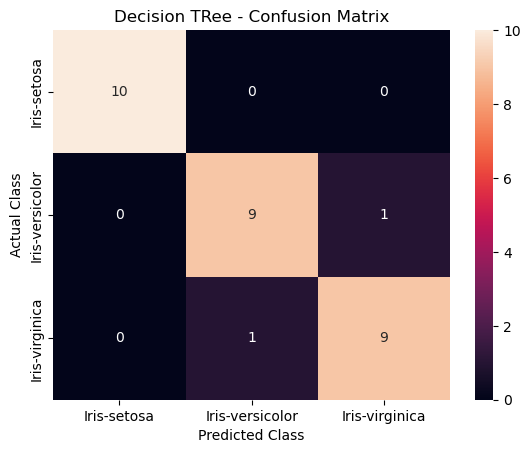

In [43]:
cm_dt = confusion_matrix(y_test, dt_pred)
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Decision TRee - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

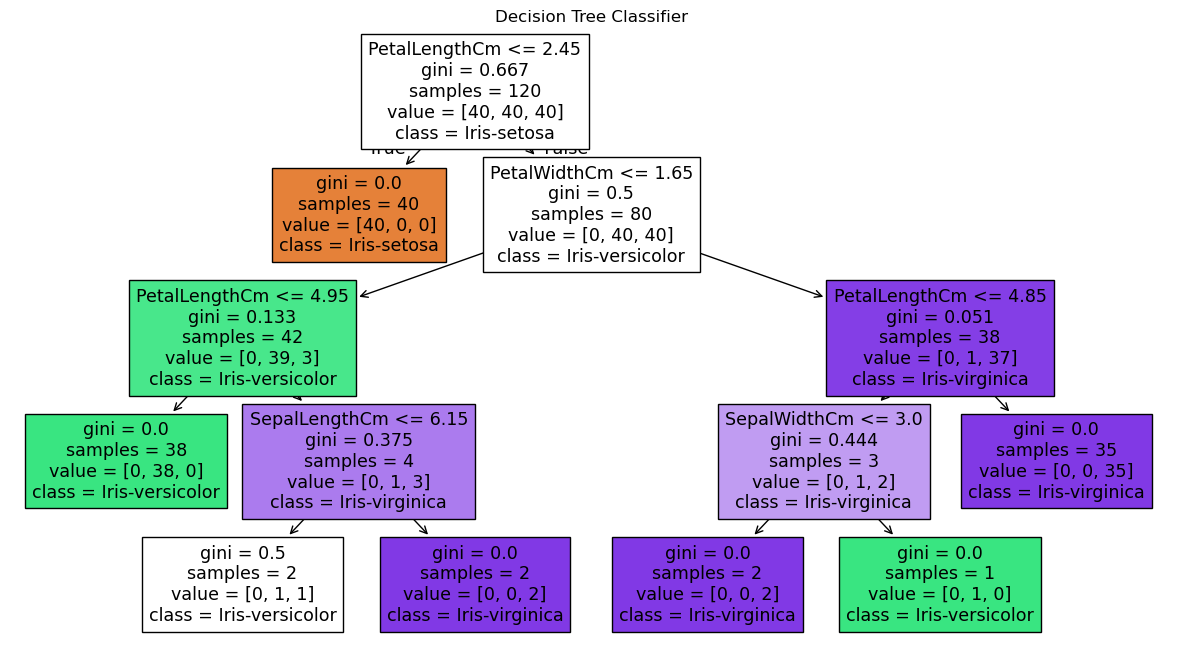

In [44]:
plt.figure(figsize=(15, 8))
plot_tree(
    dt,
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True
)

plt.title("Decision Tree Classifier")
plt.show()

In [45]:
nb = GaussianNB()

In [46]:
nb.fit(X_train, y_train)

,priors,None
,var_smoothing,1e-09


In [47]:
nb_pred = nb.predict(X_test)

In [48]:
nb_accuracy = accuracy_score(y_test, nb_pred)
nb_precision = precision_score(y_test, nb_pred, average="weighted")
nb_recall = recall_score(y_test, nb_pred, average="weighted")
nb_f1 = f1_score(y_test, nb_pred, average="weighted")

In [49]:
("Accuracy :", nb_accuracy)

('Accuracy :', 0.9666666666666667)

In [50]:
("Precision:", nb_precision)

('Precision:', 0.9696969696969696)

In [51]:
("Recall   :", nb_recall)

('Recall   :', 0.9666666666666667)

In [52]:
("F1-Score :", nb_f1)

('F1-Score :', 0.9665831244778613)

In [53]:
(
    classification_report(
        y_test,
        nb_pred,
        target_names=label_encoder.classes_
    )
)

'                 precision    recall  f1-score   support\n\n    Iris-setosa       1.00      1.00      1.00        10\nIris-versicolor       1.00      0.90      0.95        10\n Iris-virginica       0.91      1.00      0.95        10\n\n       accuracy                           0.97        30\n      macro avg       0.97      0.97      0.97        30\n   weighted avg       0.97      0.97      0.97        30\n'

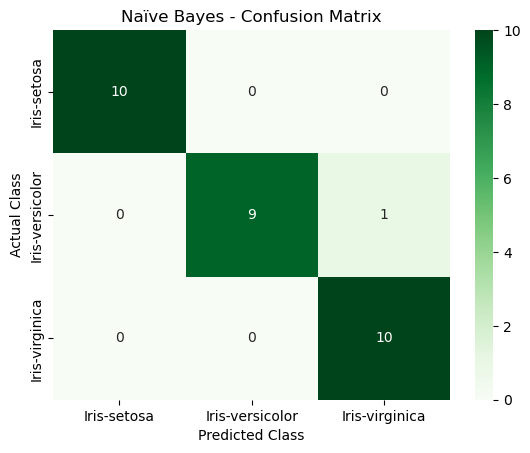

In [54]:
cm_nb = confusion_matrix(y_test, nb_pred)
sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Naïve Bayes - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [55]:
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Naïve Bayes"],
    "Accuracy": [dt_accuracy, nb_accuracy],
    "Precision": [dt_precision, nb_precision],
    "Recall": [dt_recall, nb_recall],
    "F1-Score": [dt_f1, nb_f1]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.933333,0.933333,0.933333,0.933333
1,Naïve Bayes,0.966667,0.969697,0.966667,0.966583


In [56]:
comparison_percentage = comparison.copy()

for column in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    comparison_percentage[column] = (
        comparison_percentage[column] * 100
    ).round(2)

comparison_percentage

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,93.33,93.33,93.33,93.33
1,Naïve Bayes,96.67,96.97,96.67,96.66


In [57]:
best_model = comparison.loc[
    comparison["Accuracy"].idxmax(),
    "Model"
]

("Most Suitable Model:", best_model)

('Most Suitable Model:', 'Naïve Bayes')